<a href="https://colab.research.google.com/github/ananyavj/DeepLearning/blob/main/Question%201/E_SignLanguage_MNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

BASE = "/content/drive/MyDrive/DeepLearning/datasets"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd

train_df = pd.read_csv(f"{BASE}/FNN and CNN/Sign Language MNIST/sign_mnist_train.csv")
test_df = pd.read_csv(f"{BASE}/FNN and CNN/Sign Language MNIST/sign_mnist_test.csv")

print("Training data shape : " ,train_df.shape)
print("Testing data shape : " ,test_df.shape)
print(train_df.columns.tolist()[:10])
print(train_df.head(5))

Training data shape :  (27455, 785)
Testing data shape :  (7172, 785)
['label', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5', 'pixel6', 'pixel7', 'pixel8', 'pixel9']
   label  pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  pixel8  \
0      3     107     118     127     134     139     143     146     150   
1      6     155     157     156     156     156     157     156     158   
2      2     187     188     188     187     187     186     187     188   
3      2     211     211     212     212     211     210     211     210   
4     13     164     167     170     172     176     179     180     184   

   pixel9  ...  pixel775  pixel776  pixel777  pixel778  pixel779  pixel780  \
0     153  ...       207       207       207       207       206       206   
1     158  ...        69       149       128        87        94       163   
2     187  ...       202       201       200       199       198       199   
3     210  ...       235       234       233       231       

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

(27455, 784) (27455,)
(7172, 784) (7172,)


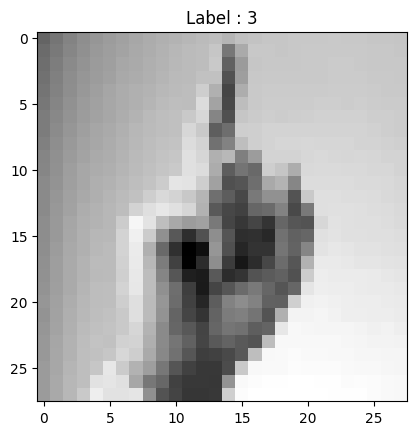

In [ ]:
X_train = train_df.drop("label", axis=1).values / 255.0
y_train = train_df["label"].values

X_test = test_df.drop("label", axis=1).values / 255.0
y_test = test_df["label"].values

print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

plt.imshow(X_train[0].reshape(28,28), cmap = "grey")
plt.title(f"Label : {y_train[0]}")
plt.show()

In [ ]:
model = keras.Sequential([
    keras.Input(shape=(784,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(25, activation="softmax")
])

In [ ]:
model.compile(
    optimizer = keras.optimizers.Adam(learning_rate=0.001),
    loss = "sparse_categorical_crossentropy",
    metrics = ["accuracy"]
)

In [ ]:
history = model.fit(
    X_train, y_train,
    epochs = 22,
    batch_size = 32,
    validation_split = 0.1
)

Epoch 1/22
773/773 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.3549 - loss: 2.1034 - val_accuracy: 0.5703 - val_loss: 1.4086
Epoch 2/22
773/773 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.6215 - loss: 1.1921 - val_accuracy: 0.7003 - val_loss: 0.9576
Epoch 3/22
773/773 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.7195 - loss: 0.8730 - val_accuracy: 0.7837 - val_loss: 0.6923
Epoch 4/22
773/773 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.7912 - loss: 0.6596 - val_accuracy: 0.8216 - val_loss: 0.5371
Epoch 5/22
773/773 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8457 - loss: 0.5004 - val_accuracy: 0.8988 - val_loss: 0.3551
Epoch 6/22
773/773 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8792 - loss: 0.3895 - val_accuracy: 0.9159 - val_loss: 0.2939
Epoch 7/22
773/773 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9076 - loss: 0.3029 - val_accuracy: 0.9093 - val_loss: 0.2810
Epoch 8/22
773/773 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9312 - loss: 0.2344 - val_accuracy: 0.

In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print("Test loss is : ", test_loss)
print("Test accuracy is : ", test_accuracy)

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7398 - loss: 1.6181
Test loss is :  1.6181235313415527
Test accuracy is :  0.7398215532302856


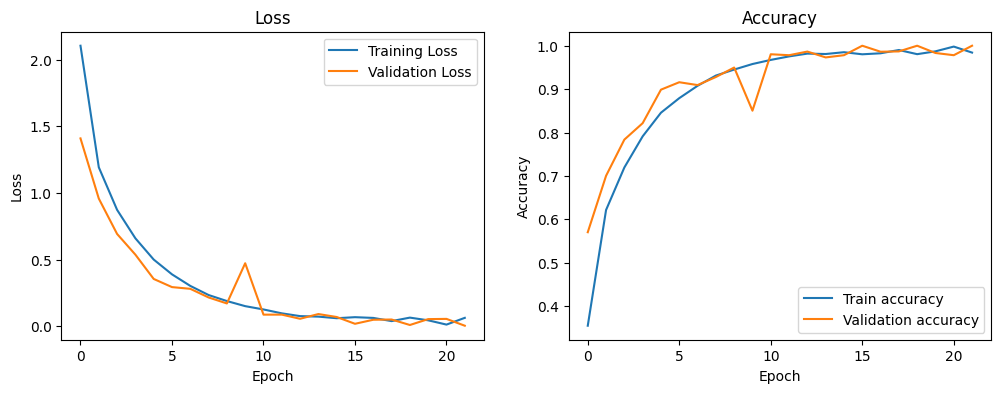

In [ ]:
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Train accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy")
plt.legend()


plt.show()
